100%|██████████| 58.4k/58.4k [00:00<00:00, 3.72MB/s]

Extracting files...


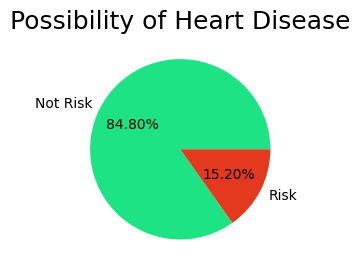

In [1]:
#using scikit learn
from pandas.plotting import autocorrelation_plot
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Download latest version
path = kagglehub.dataset_download("dileep070/heart-disease-prediction-using-logistic-regression")

# Construct the full path to the CSV file within the downloaded directory
csv_file_path = os.path.join(path, 'framingham.csv')

heart_df = pd.read_csv(csv_file_path)
heart_df.tail()
#mode is for binary datatypes, mean is for the rest
heart_df["education"]=heart_df["education"].fillna(heart_df["education"].mode()[0])
heart_df["cigsPerDay"]=heart_df["cigsPerDay"].fillna(heart_df["cigsPerDay"].mode()[0])
heart_df["BPMeds"]=heart_df["BPMeds"].fillna(heart_df["BPMeds"].mode()[0])
heart_df["totChol"] = heart_df["totChol"].fillna(heart_df["totChol"].mean())
heart_df["BMI"] = heart_df["BMI"].fillna(heart_df["BMI"].mean())
heart_df["heartRate"] = heart_df["heartRate"].fillna(heart_df["heartRate"].mean())
heart_df["glucose"]=heart_df["glucose"].fillna(heart_df["glucose"].mean())
heart_df.isnull().sum()
heart_df.isnull().sum()
#make a pie chart to visualize whos at risk vs who isnt
plt.subplot(1,2,2)
labels = ["Not Risk", "Risk"]
colors = ["#1EE384","#E3391E"]
heart_df["TenYearCHD"].value_counts().plot(kind="pie",autopct ="%1.2f%%",labels=labels,colors = colors)
plt.title("Possibility of Heart Disease",size=18)
plt.ylabel("") #makes the plot a bit smaller

#make a bar chart

for col in ["male","education","currentSmoker","BPMeds","prevalentStroke","prevalentHyp","diabetes"]:
  path

-4346.264779152365
-148.70672276805357
-142.9649362310784
-141.54530307157367
-141.060319659308
-140.87031585891603
-140.79025912753815
-140.75505002269915
-140.73914503180953
-140.73183498915878
-140.72843666694826
-140.72684471255332
-140.72609508950472
-140.72574086052302
-140.72557306887177
-140.7254934578617
-140.72545564250743
-140.7254376661433
-140.72542911609162
-140.7254250479478
-140.72542311181695
-140.72542219020235
-140.7254217514527
-140.72542154256132
-140.7254214431011
-140.7254213957428
-140.72542137319252
-140.72542136245457
-140.72542135734136
-140.72542135490647


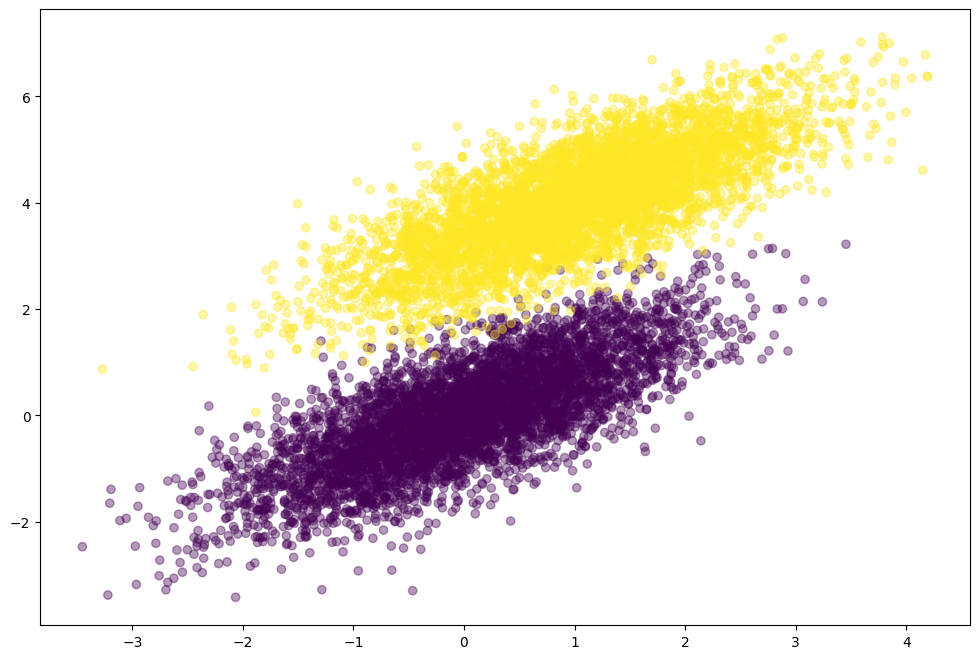

In [8]:
#from scratch
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
#generate some data
np.random.seed(12)
num_observations = 5000

x1 = np.random.multivariate_normal([0, 0], [[1, .75],[.75, 1]], num_observations)
x2 = np.random.multivariate_normal([1, 4], [[1, .75],[.75, 1]], num_observations)

simulated_separableish_features = np.vstack((x1, x2)).astype(np.float32)
simulated_labels = np.hstack((np.zeros(num_observations),
                              np.ones(num_observations)))
plt.figure(figsize=(12,8))
plt.scatter(simulated_separableish_features[:, 0], simulated_separableish_features[:,1], c = simulated_labels, alpha = .4)

def sigmoid(scores):
  return 1/(1+np.exp(-scores))

def log_likelihood(features, target, weights):
  scores = np.dot(features, weights) #features are measurable properties weights are how significant they are
  ll = np.sum(target*scores - np.log(1+np.exp(scores))) #takes the loglikelihood function
  return ll

#nabla or ∇ represents the gradient symbol

def logistic_regression(features, target, num_steps, learning_rate, add_intercept = False):#no intercept means no bias
   if add_intercept:
    intercept = np.ones((features.shape[0], 1))
    features = np.hstack((intercept, features))
   weights = np.zeros(features.shape[1])

   for step in range(num_steps): # Changed xrange to range for Python 3 compatibility
    scores = np.dot(features, weights)
    predictions = sigmoid(scores)

    output_error_signal = target - predictions
    gradient = np.dot(features.T, output_error_signal)
    weights += learning_rate * gradient

    if step % 10000 == 0:
      print (log_likelihood(features, target, weights))
   return weights
weights = logistic_regression(simulated_separableish_features, simulated_labels, num_steps = 300000, learning_rate = 5e-5, add_intercept=True)


Gradient
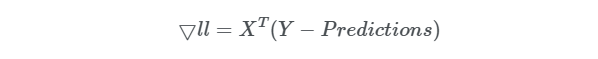

Loglikelihood Function:

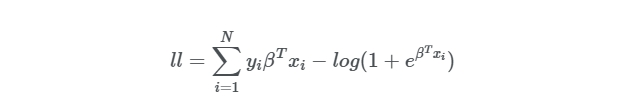


Uses sigmoid function to make values between 0 and 1. We want to make it so we have half and half.

g(z) = 1/(1 + e^-z)

Threshold: the seperating point. Greater than threshold is 1, less than threshold it is 0.

We can't use the cost function from the linear regression because we don't have continuous values.



1.   Penalise predictions far from the true label
2.   Reward Predictions that are close to the true label

So we use a piecewise model.

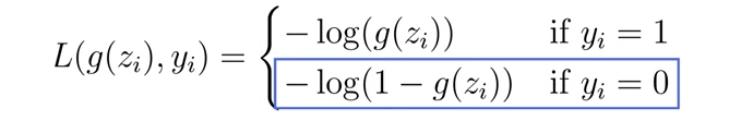

We can use gradient descent like we did in linear regression w - learning rate(partial derivative)

